In [2]:
import import_function as fun 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from pyEDM import *
from seaborn import heatmap, kdeplot, histplot, color_palette

# R functions
import os
os.environ["R_LIBS_USER"] = os.path.expanduser("~/R/library")
from rpy2.robjects.packages import importr
detectBatch = importr('cpm').detectChangePointBatch
rdollar     = importr('base').__dict__['$']
import warnings
from rpy2.rinterface import RRuntimeWarning
warnings.filterwarnings("ignore", category=RRuntimeWarning)
import os, string
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import kpss

/home/eulalie/Documents/eulalie/etude/cesure/taiwan/travail/NTU_ecoinformatic/ecoinfo/lib/python3.14/site-packages/pyEDM/AuxFunc.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## First tests (preprocess, simplex and smap algorithms)
### Preprocess
    Streamflow data

RMSE mult-Additif: 36151.6175
RMSE add-mult: 10.4975
RMSE Additif: 0.5291
RMSE Multiplicatif: 3.2373
KPSS (original) : p-value = 0.0100
KPSS (detrended additive) : p-value = 0.1000
KPSS (detrended multiplicative) : p-value = 0.1000


/tmp/ipykernel_120890/1330716821.py:102: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_original = kpss(fun.normalize_series(mean_flow_fdv1), regression='c')  # 'c' = constante (pour tendance)
/tmp/ipykernel_120890/1330716821.py:102: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_original = kpss(fun.normalize_series(mean_flow_fdv1), regression='c')  # 'c' = constante (pour tendance)
/tmp/ipykernel_120890/1330716821.py:106: InterpolationWarning: The test statistic is outside of the range of p-values available in t

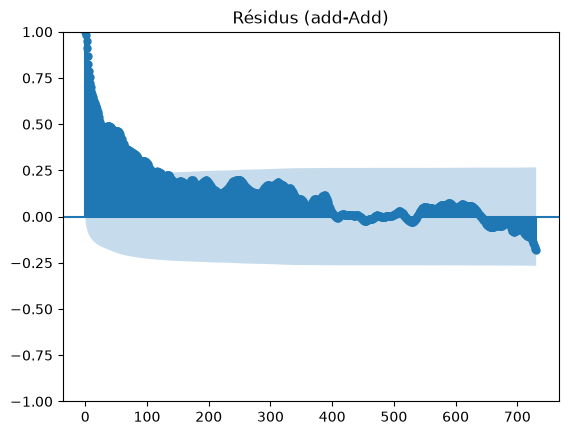

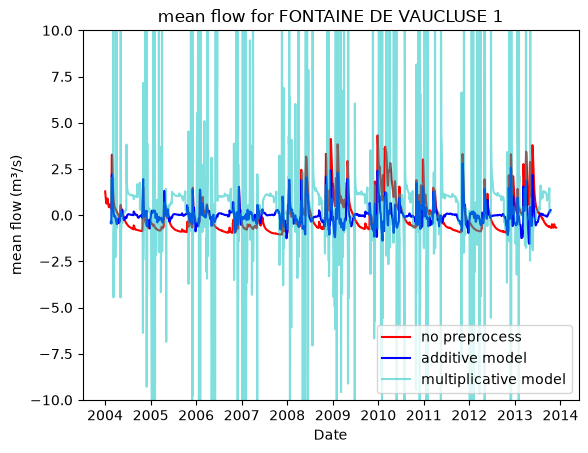

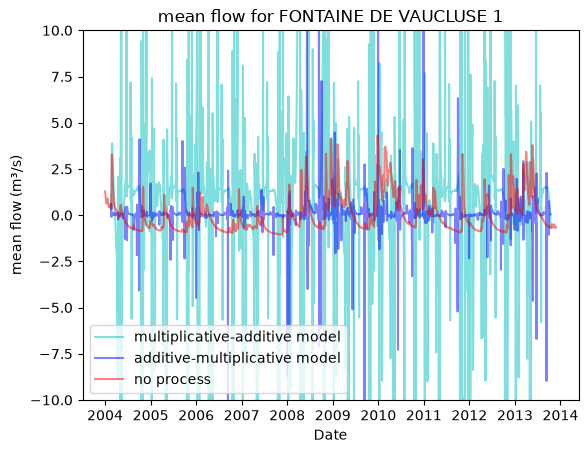

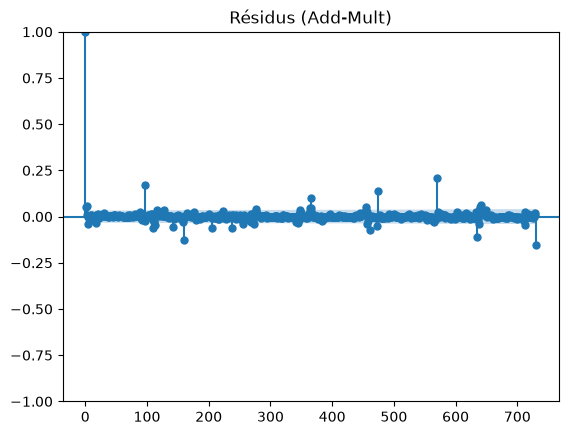

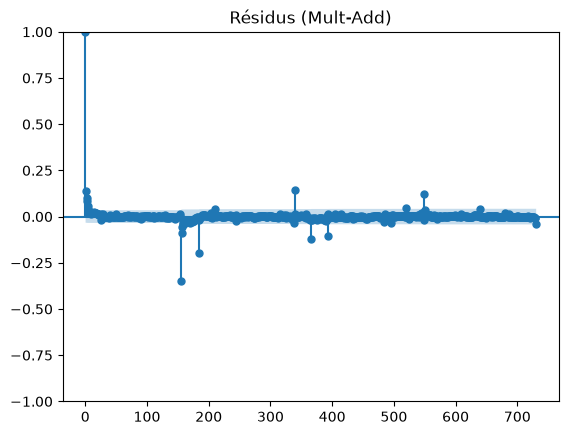

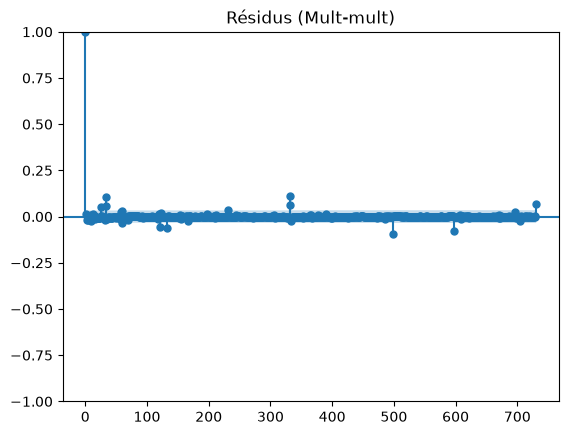

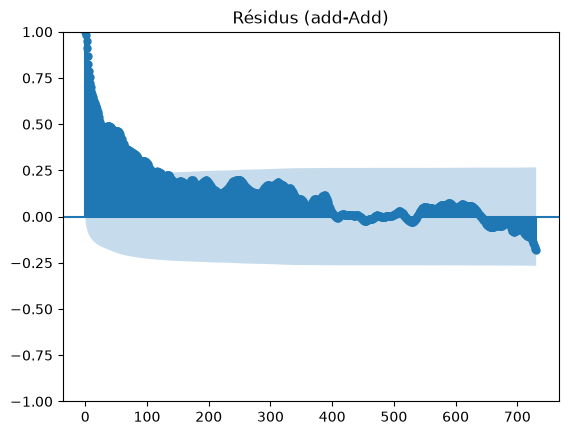

In [3]:
fdv1 = pd.read_csv('donnees/rivers_02-13.csv', sep=';', parse_dates=['date'])
fdv1 = fdv1[(fdv1['city']=='FONTAINE DE VAUCLUSE 1') & (fdv1['date'] > '2004-01-01')]
mean_flow_fdv1 = fdv1['mean_flow']
river_flow = fun.normalize_series(mean_flow_fdv1)


normalize_mean_flow_fdv1_a = fun.normalize_series(mean_flow_fdv1)
deseason_mean_flow_fdv1_a = fun.deseason_add(normalize_mean_flow_fdv1_a, 1)
detrend_mean_flow_fdv1_a = fun.detrend_add(deseason_mean_flow_fdv1_a)
river_flow_a = detrend_mean_flow_fdv1_a
plt.figure()
plt.plot(fdv1['date'], fun.normalize_series(mean_flow_fdv1), label = 'no preprocess', color='r')
plt.plot(fdv1['date'], detrend_mean_flow_fdv1_a, label = 'additive model', color='b')


normalize_mean_flow_fdv1_m = fun.normalize_series(mean_flow_fdv1)
deseason_mean_flow_fdv1_m = fun.deseason_mult(normalize_mean_flow_fdv1_m, 1)
detrend_mean_flow_fdv1_m = fun.detrend_mult(deseason_mean_flow_fdv1_m)
river_flow_m = deseason_mean_flow_fdv1_m
plt.plot(fdv1['date'], detrend_mean_flow_fdv1_m, label = 'multiplicative model', color='c', alpha=0.5)


plt.title('mean flow for FONTAINE DE VAUCLUSE 1')
plt.xlabel('Date')
plt.ylabel('mean flow (m³/s)')
plt.legend()
plt.ylim(-10, 10)


# ===== Additif =====
Y_a = normalize_mean_flow_fdv1_a
Y_pred_add = Y_a - detrend_mean_flow_fdv1_a # T + S
y_true_a, y_pred_a = Y_a.align(Y_pred_add, join='inner')
y_true_a = y_true_a.dropna()
y_pred_a = y_pred_a.dropna()
y_true_a, y_pred_a = y_true_a.align(y_pred_a, join='inner')

rmse_a = np.sqrt(mean_squared_error(y_true_a, y_pred_a))

# ===== Multiplicatif =====
Y_m = normalize_mean_flow_fdv1_m
Y_pred_mult = Y_m / detrend_mean_flow_fdv1_m  # T * S
y_true_m, y_pred_m = Y_m.align(Y_pred_mult, join='inner')
y_true_m = y_true_m.dropna()
y_pred_m = y_pred_m.dropna()
y_true_m, y_pred_m = y_true_m.align(y_pred_m, join='inner')
rmse_m = np.sqrt(mean_squared_error(y_true_m, y_pred_m))


## MODELE MIXTE 

# Modèle Additif-Multiplicatif (Y = T + S×R)
detrended_add = fun.detrend_add(fun.normalize_series(mean_flow_fdv1))
deseasoned_add_mult = fun.deseason_mult(detrended_add, 1)
residuals_add_mult = deseasoned_add_mult
river_flow_am = deseasoned_add_mult

# Modèle Multiplicatif-Additif (Y = T×S + R)
detrended_mult = fun.detrend_mult(fun.normalize_series(mean_flow_fdv1))
deseasoned_mult_add = fun.deseason_add(detrended_mult, 1)
residuals_mult_add = deseasoned_mult_add
river_flow_ma = deseasoned_mult_add

# ===== Additif =====
Y_am = deseasoned_add_mult
Y_pred_add_mult = (deseasoned_add_mult - detrended_add) + (detrended_add / deseasoned_add_mult)
y_true_am, y_pred_am = Y_am.align(Y_pred_add_mult, join='inner')
y_true_am = y_true_am.dropna()
y_pred_am = y_pred_am.dropna()
y_true_am, y_pred_am = y_true_am.align(y_pred_am, join='inner')

rmse_am = np.sqrt(mean_squared_error(y_true_am, y_pred_am))

# ===== Mult-Add=====
Y_ma = deseasoned_mult_add
Y_pred_mult_add = (deseasoned_mult_add / detrended_mult) * (detrended_mult - deseasoned_mult_add)
y_true_ma, y_pred_ma = Y_ma.align(Y_pred_mult_add, join='inner')
y_true_ma = y_true_ma.dropna()
y_pred_ma = y_pred_ma.dropna()
y_true_ma, y_pred_ma = y_true_ma.align(y_pred_ma, join='inner')
rmse_ma = np.sqrt(mean_squared_error(y_true_ma, y_pred_ma))

plt.figure()
plt.plot(fdv1['date'], deseasoned_mult_add, label = 'multiplicative-additive model', color='c', alpha=0.5)
plt.plot(fdv1['date'], deseasoned_add_mult, label = 'additive-multiplicative model', color='b', alpha=0.5)
plt.plot(fdv1['date'], fun.normalize_series(mean_flow_fdv1), label = 'no process', color='r', alpha=0.5)

plt.title('mean flow for FONTAINE DE VAUCLUSE 1')
plt.xlabel('Date')
plt.ylabel('mean flow (m³/s)')
plt.legend()
plt.ylim(-10, 10)

# COMPARAISON

print(f"RMSE mult-Additif: {rmse_ma:.4f}")
print(f"RMSE add-mult: {rmse_am:.4f}")
print(f"RMSE Additif: {rmse_a:.4f}")
print(f"RMSE Multiplicatif: {rmse_m:.4f}")

# Test KPSS sur la série originale (doit être NON stationnaire)
kpss_original = kpss(fun.normalize_series(mean_flow_fdv1), regression='c')  # 'c' = constante (pour tendance)
print(f"KPSS (original) : p-value = {kpss_original[1]:.4f}")  # Doit être < 0.05

# Test KPSS après detrend (doit être stationnaire)
kpss_detrended = kpss(detrended_add.dropna(), regression='c')
print(f"KPSS (detrended additive) : p-value = {kpss_detrended[1]:.4f}")  # Doit être > 0.05

kpss_detrended = kpss(detrended_mult.dropna(), regression='c')
print(f"KPSS (detrended multiplicative) : p-value = {kpss_detrended[1]:.4f}")

plot_acf(residuals_add_mult.dropna(), lags=730, alpha=0.05, title="Résidus (Add-Mult)")
plot_acf(residuals_mult_add.dropna(), lags=730, alpha=0.05, title="Résidus (Mult-Add)")
plot_acf(deseason_mean_flow_fdv1_m.dropna(), lags=730, alpha=0.05, title="Résidus (Mult-mult)")
plot_acf(deseason_mean_flow_fdv1_a.dropna(), lags=730, alpha=0.05, title="Résidus (add-Add)")


![title](img/process_flow.png)

    Precipitation

RMSE mult-Additif: 52022.6857
RMSE add-mult : 77.3248
RMSE Additif: 0.9478
RMSE Multiplicatif: 2.2480
KPSS (original) : p-value = 0.1000
KPSS (detrended additive) : p-value = 0.1000
KPSS (detrended multiplicative) : p-value = 0.1000


/tmp/ipykernel_120890/2482517757.py:98: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_original = kpss(rain_, regression='c')  # 'c' = constante (pour tendance)
/tmp/ipykernel_120890/2482517757.py:98: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_original = kpss(rain_, regression='c')  # 'c' = constante (pour tendance)
/tmp/ipykernel_120890/2482517757.py:102: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value

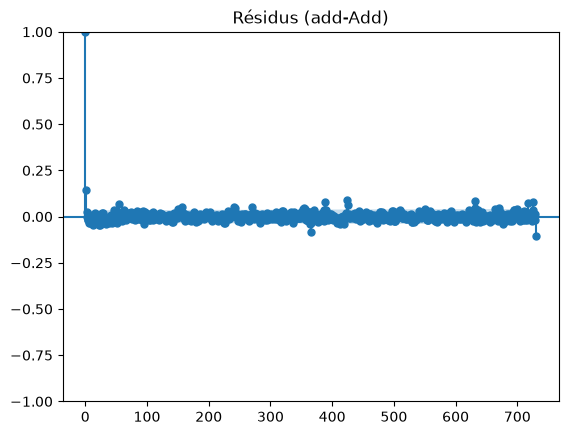

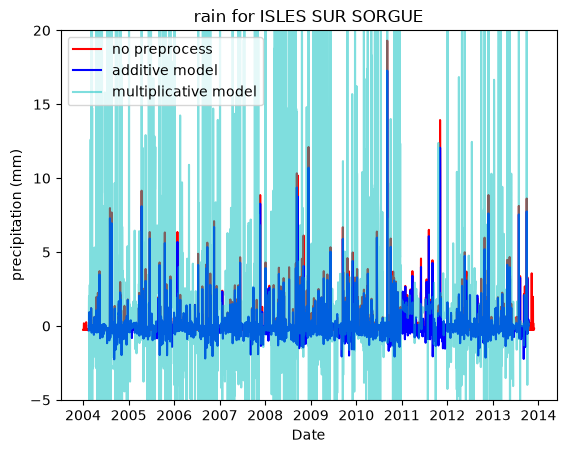

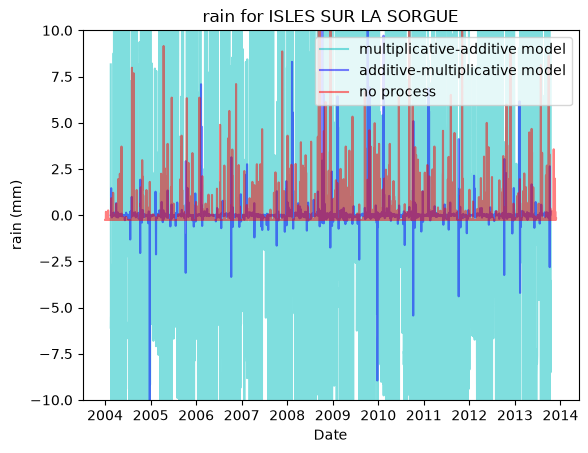

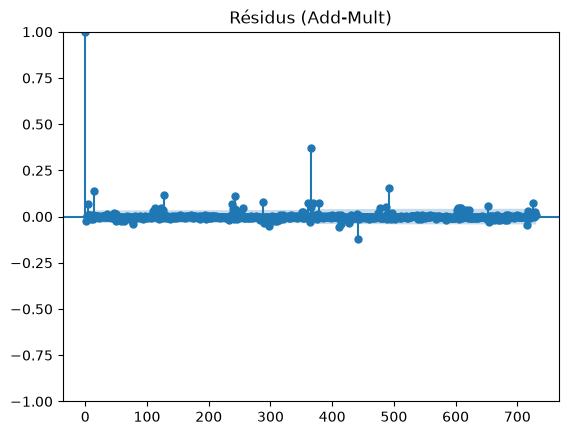

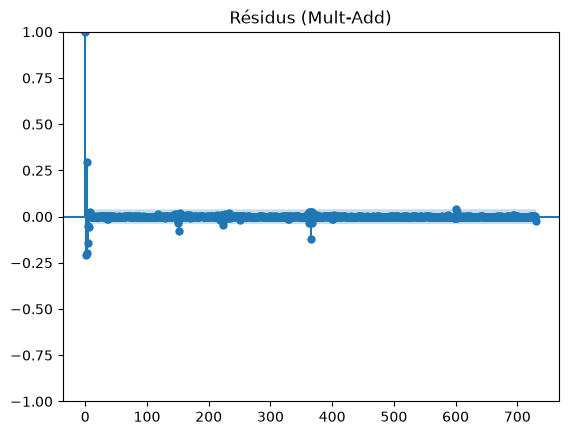

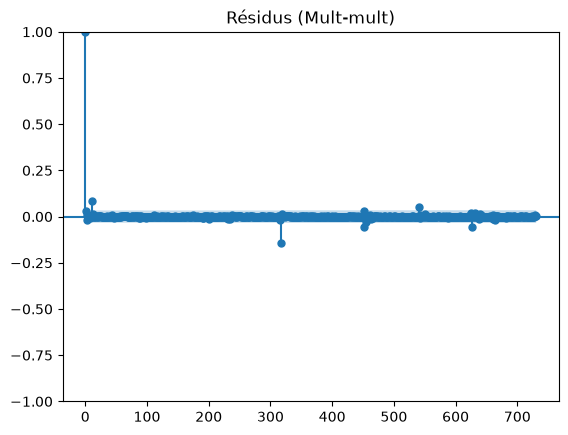

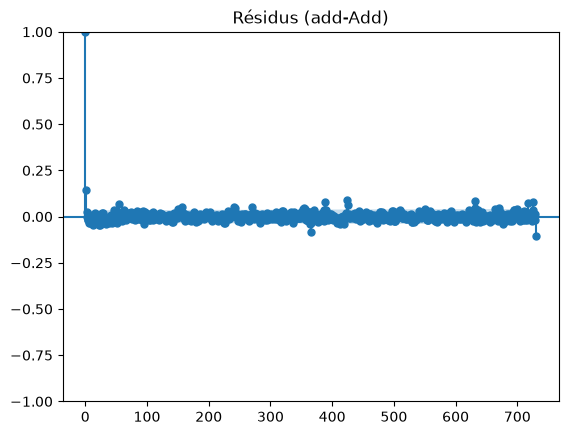

In [5]:
meteo = pd.read_csv('donnees/meteo_02-13.csv', sep = ';', parse_dates=['date'])
meteo = meteo[(meteo['city'] == 'ISLE SUR SORGUE') & (meteo['date'] > '2004-01-01')]
rain = meteo['precipitation']

rain_ = fun.normalize_series(rain)

normalize_rain = fun.normalize_series(rain)
deseason_rain= fun.deseason_add(normalize_rain, 1)
detrend_rain = fun.detrend_add(deseason_rain)
rain_a = detrend_rain
plt.figure()
plt.plot(meteo['date'], rain_, label = 'no preprocess', color = 'r')
plt.plot(meteo['date'], rain_a, label = 'additive model', color ='b')

normalize_rain = fun.normalize_series(rain)
deseason_rain= fun.deseason_mult(normalize_rain, 1)
detrend_rain = fun.detrend_mult(deseason_rain)
rain_m = detrend_rain
plt.plot(meteo['date'], rain_m, label = 'multiplicative model', color ='c', alpha=0.5)

plt.title('rain for ISLES SUR SORGUE')
plt.xlabel('Date')
plt.ylabel('precipitation (mm)')
plt.legend()
plt.ylim(-5, 20)

# ===== Additif =====
Y_a = normalize_rain
Y_pred_add = Y_a - rain_a  # T + S
y_true_a, y_pred_a = Y_a.align(Y_pred_add, join='inner')
y_true_a = y_true_a.dropna()
y_pred_a = y_pred_a.dropna()
y_true_a, y_pred_a = y_true_a.align(y_pred_a, join='inner')

rmse_a = np.sqrt(mean_squared_error(y_true_a, y_pred_a))

# ===== Multiplicatif =====
Y_m = normalize_rain
Y_pred_mult = Y_m / rain_m  # T * S
y_true_m, y_pred_m = Y_m.align(Y_pred_mult, join='inner')
y_true_m = y_true_m.dropna()
y_pred_m = y_pred_m.dropna()
y_true_m, y_pred_m = y_true_m.align(y_pred_m, join='inner')
rmse_m = np.sqrt(mean_squared_error(y_true_m, y_pred_m))

## MODELE MIXTE 

# Modèle Additif-Multiplicatif (Y = T + S×R)
detrended_add = fun.detrend_add(rain_)
deseasoned_add_mult = fun.deseason_mult(detrended_add, 1)
residuals_add_mult = deseasoned_add_mult
rain_am = deseasoned_add_mult

# Modèle Multiplicatif-Additif (Y = T×S + R)
detrended_mult = fun.detrend_mult(rain_)
deseasoned_mult_add = fun.deseason_add(detrended_mult, 1)
residuals_mult_add = deseasoned_mult_add
rain_ma = deseasoned_mult_add

# ===== Additif =====
Y_am = deseasoned_add_mult
Y_pred_add_mult = (deseasoned_add_mult - detrended_add) + (detrended_add / deseasoned_add_mult)
y_true_am, y_pred_am = Y_am.align(Y_pred_add_mult, join='inner')
y_true_am = y_true_am.dropna()
y_pred_am = y_pred_am.dropna()
y_true_am, y_pred_am = y_true_am.align(y_pred_am, join='inner')

rmse_am = np.sqrt(mean_squared_error(y_true_am, y_pred_am)) 

# ===== Mult-Add=====
Y_ma = deseasoned_mult_add
Y_pred_mult_add = (deseasoned_mult_add / detrended_mult) * (detrended_mult - deseasoned_mult_add)
y_true_ma, y_pred_ma = Y_ma.align(Y_pred_mult_add, join='inner')
y_true_ma = y_true_ma.dropna()
y_pred_ma = y_pred_ma.dropna()
y_true_ma, y_pred_ma = y_true_ma.align(y_pred_ma, join='inner')
rmse_ma = np.sqrt(mean_squared_error(y_true_ma, y_pred_ma))

plt.figure()
plt.plot(meteo['date'], deseasoned_mult_add, label = 'multiplicative-additive model', color='c', alpha=0.5)
plt.plot(meteo['date'], deseasoned_add_mult, label = 'additive-multiplicative model', color='b', alpha=0.5)
plt.plot(meteo['date'], rain_, label = 'no process', color='r', alpha=0.5)

plt.title('rain for ISLES SUR LA SORGUE')
plt.xlabel('Date')
plt.ylabel('rain (mm)')
plt.legend()
plt.ylim(-10, 10)

# COMPARAISON

print(f"RMSE mult-Additif: {rmse_ma:.4f}")
print(f"RMSE add-mult : {rmse_am:.4f}")
print(f"RMSE Additif: {rmse_a:.4f}")
print(f"RMSE Multiplicatif: {rmse_m:.4f}")

# Test KPSS sur la série originale (doit être NON stationnaire)
kpss_original = kpss(rain_, regression='c')  # 'c' = constante (pour tendance)
print(f"KPSS (original) : p-value = {kpss_original[1]:.4f}")  # Doit être < 0.05

# Test KPSS après detrend (doit être stationnaire)
kpss_detrended = kpss(detrended_add.dropna(), regression='c')
print(f"KPSS (detrended additive) : p-value = {kpss_detrended[1]:.4f}")  # Doit être > 0.05

kpss_detrended = kpss(detrended_mult.dropna(), regression='c')
print(f"KPSS (detrended multiplicative) : p-value = {kpss_detrended[1]:.4f}")

plot_acf(residuals_add_mult.dropna(), lags=730, alpha=0.05, title="Résidus (Add-Mult)")
plot_acf(residuals_mult_add.dropna(), lags=730, alpha=0.05, title="Résidus (Mult-Add)")
plot_acf(rain_m.dropna(), lags=730, alpha=0.05, title="Résidus (Mult-mult)")
plot_acf(rain_a.dropna(), lags=730, alpha=0.05, title="Résidus (add-Add)")


![title](img/process_rain.png)

    Groundwater

RMSE mult-Additif: 2727.9691
RMSE add-mult : 483.2842
RMSE Additif: 0.3098
RMSE Multiplicatif: 48.9900
KPSS (original) : p-value = 0.1000
KPSS (detrended additive) : p-value = 0.1000
KPSS (detrended multiplicative) : p-value = 0.1000


/tmp/ipykernel_120890/2477151028.py:94: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_original = kpss(depth, regression='c')  # 'c' = constante (pour tendance)
/tmp/ipykernel_120890/2477151028.py:94: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_original = kpss(depth, regression='c')  # 'c' = constante (pour tendance)
/tmp/ipykernel_120890/2477151028.py:98: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value 

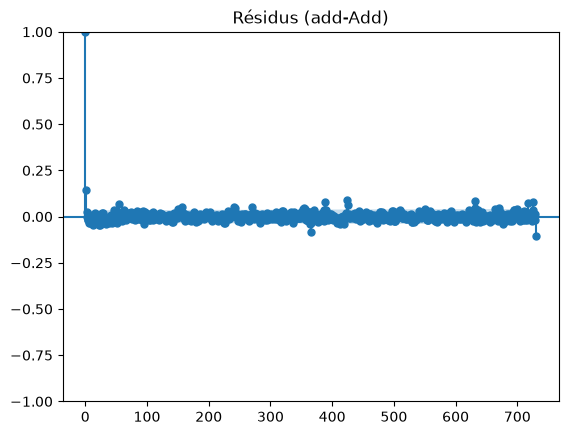

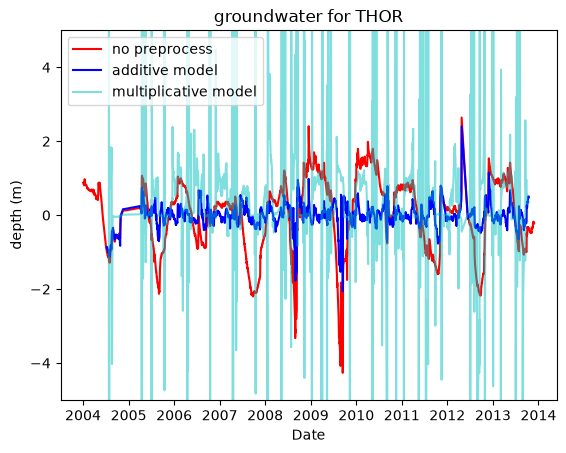

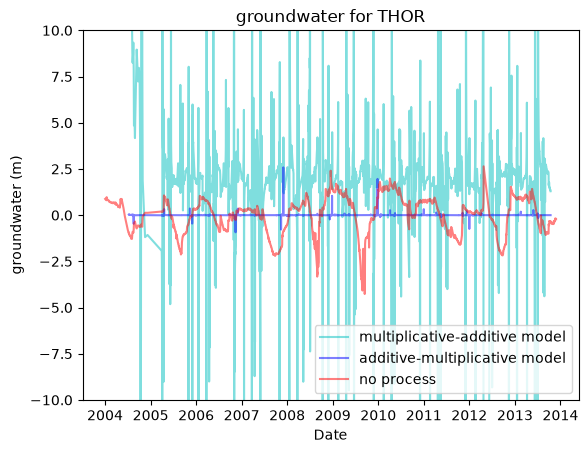

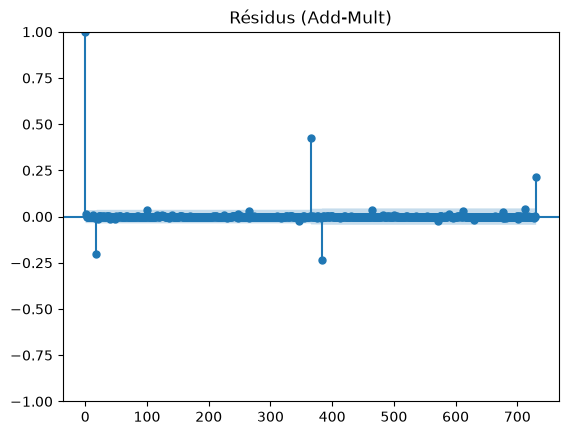

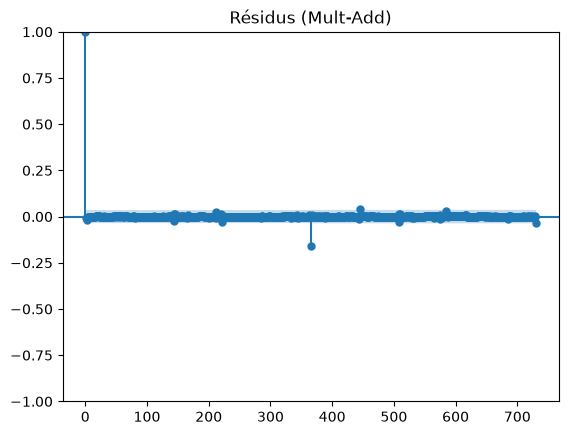

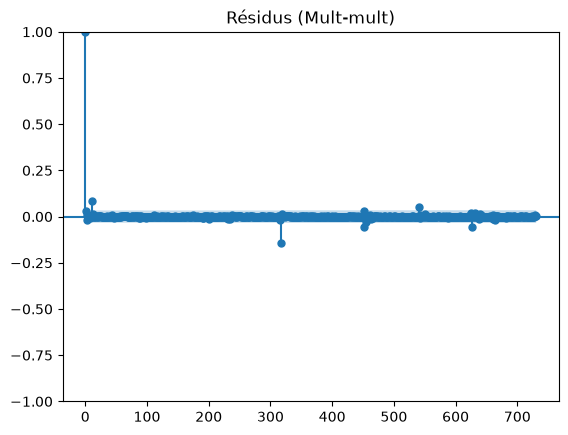

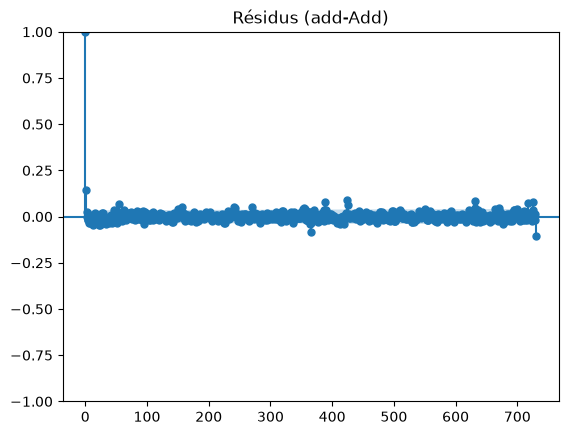

In [6]:
ground_water = pd.read_csv('donnees/groundwater_02-13.csv', sep=';', parse_dates = ['date'])
ground_water = ground_water[(ground_water['city']=='THOR') & (ground_water['date'] > '2004-01-01')]
depth = ground_water['NGF_depth']
depth = fun.normalize_series(depth)

deseason_depth= fun.deseason_add(depth, 1)
detrend_depth = fun.detrend_add(deseason_depth)
depth_a = detrend_depth
plt.figure()
plt.plot(ground_water['date'], depth, label = 'no preprocess', color = 'r')
plt.plot(ground_water['date'], depth_a, label = 'additive model', color ='b')

deseason_depth= fun.deseason_mult(depth, 1)
detrend_depth = fun.detrend_mult(deseason_depth)
depth_m = detrend_depth
plt.plot(ground_water['date'], depth_m, label = 'multiplicative model', color ='c', alpha=0.5)

plt.title('groundwater for THOR')
plt.xlabel('Date')
plt.ylabel('depth (m)')
plt.legend()
plt.ylim(-5, 5)

# ===== Additif =====
Y_a = depth
Y_pred_add = Y_a - depth_a  # T + S
y_true_a, y_pred_a = Y_a.align(Y_pred_add, join='inner')
y_true_a = y_true_a.dropna()
y_pred_a = y_pred_a.dropna()
y_true_a, y_pred_a = y_true_a.align(y_pred_a, join='inner')
rmse_a = np.sqrt(mean_squared_error(y_true_a, y_pred_a))

# ===== Multiplicatif =====
Y_m = depth
Y_pred_mult = Y_m / depth_m  # T * S
y_true_m, y_pred_m = Y_m.align(Y_pred_mult, join='inner')
y_true_m = y_true_m.dropna()
y_pred_m = y_pred_m.dropna()
y_true_m, y_pred_m = y_true_m.align(y_pred_m, join='inner')
rmse_m = np.sqrt(mean_squared_error(y_true_m, y_pred_m))

## MODELE MIXTE 

# Modèle Additif-Multiplicatif (Y = T + S×R)
detrended_add = fun.detrend_add(depth)
deseasoned_add_mult = fun.deseason_mult(detrended_add, 1)
residuals_add_mult = deseasoned_add_mult
depth_am = deseasoned_add_mult

# Modèle Multiplicatif-Additif (Y = T×S + R)
detrended_mult = fun.detrend_mult(depth)
deseasoned_mult_add = fun.deseason_add(detrended_mult, 1)
residuals_mult_add = deseasoned_mult_add
depth_ma = deseasoned_mult_add

# ===== Additif =====
Y_am = deseasoned_add_mult
Y_pred_add_mult = (deseasoned_add_mult - detrended_add) + (detrended_add / deseasoned_add_mult)
y_true_am, y_pred_am = Y_am.align(Y_pred_add_mult, join='inner')
y_true_am = y_true_am.dropna()
y_pred_am = y_pred_am.dropna()
y_true_am, y_pred_am = y_true_am.align(y_pred_am, join='inner')

rmse_am = np.sqrt(mean_squared_error(y_true_am, y_pred_am)) 

# ===== Mult-Add=====
Y_ma = deseasoned_mult_add
Y_pred_mult_add = (deseasoned_mult_add / detrended_mult) * (detrended_mult - deseasoned_mult_add)
y_true_ma, y_pred_ma = Y_ma.align(Y_pred_mult_add, join='inner')
y_true_ma = y_true_ma.dropna()
y_pred_ma = y_pred_ma.dropna()
y_true_ma, y_pred_ma = y_true_ma.align(y_pred_ma, join='inner')
rmse_ma = np.sqrt(mean_squared_error(y_true_ma, y_pred_ma))

plt.figure()
plt.plot(ground_water['date'], deseasoned_mult_add, label = 'multiplicative-additive model', color='c', alpha=0.5)
plt.plot(ground_water['date'], deseasoned_add_mult, label = 'additive-multiplicative model', color='b', alpha=0.5)
plt.plot(ground_water['date'], depth, label = 'no process', color='r', alpha=0.5)

plt.title('groundwater for THOR')
plt.xlabel('Date')
plt.ylabel('groundwater (m)')
plt.legend()
plt.ylim(-10, 10)

# COMPARAISON

print(f"RMSE mult-Additif: {rmse_ma:.4f}")
print(f"RMSE add-mult : {rmse_am:.4f}")
print(f"RMSE Additif: {rmse_a:.4f}")
print(f"RMSE Multiplicatif: {rmse_m:.4f}")

# Test KPSS sur la série originale (doit être NON stationnaire)
kpss_original = kpss(depth, regression='c')  # 'c' = constante (pour tendance)
print(f"KPSS (original) : p-value = {kpss_original[1]:.4f}")  # Doit être < 0.05

# Test KPSS après detrend (doit être stationnaire)
kpss_detrended = kpss(detrended_add.dropna(), regression='c')
print(f"KPSS (detrended additive) : p-value = {kpss_detrended[1]:.4f}")  # Doit être > 0.05

kpss_detrended = kpss(detrended_mult.dropna(), regression='c')
print(f"KPSS (detrended multiplicative) : p-value = {kpss_detrended[1]:.4f}")

plot_acf(residuals_add_mult.dropna(), lags=730, alpha=0.05, title="Résidus (Add-Mult)")
plot_acf(residuals_mult_add.dropna(), lags=730, alpha=0.05, title="Résidus (Mult-Add)")
plot_acf(rain_m.dropna(), lags=730, alpha=0.05, title="Résidus (Mult-mult)")
plot_acf(rain_a.dropna(), lags=730, alpha=0.05, title="Résidus (add-Add)")


![title](img/process_groundwater.png)

### Simplex algorithm

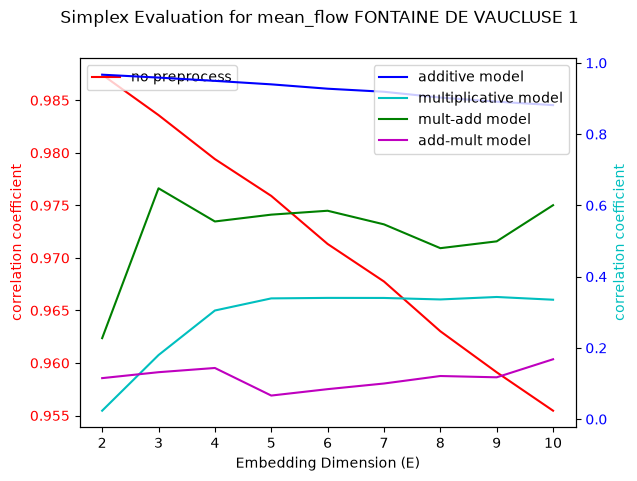

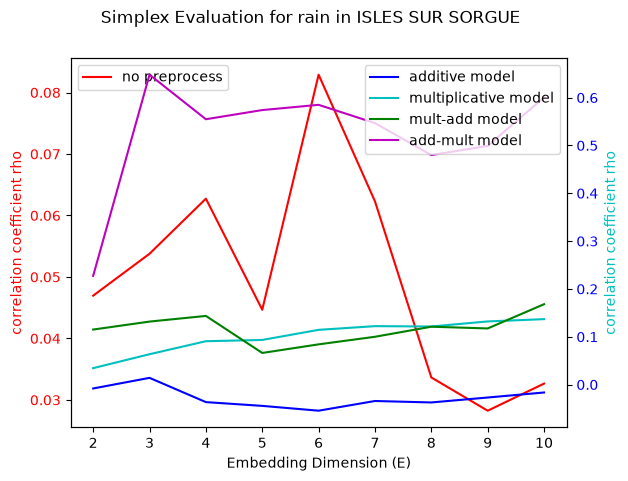

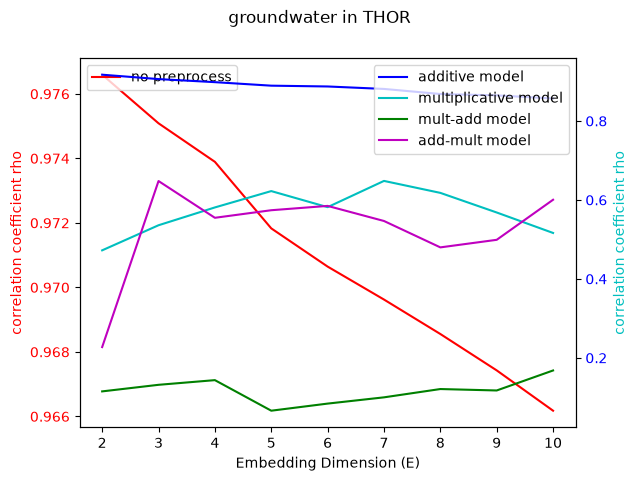

In [ ]:
lib = "1 1000"
pred = "1001 3000"
result = fun.evaluate_dimension(fun.normalize_series(mean_flow_fdv1), lib=lib, pred=pred)
result_a = fun.evaluate_dimension(river_flow_a, lib=lib, pred=pred)
result_m = fun.evaluate_dimension(river_flow_m, lib=lib, pred=pred)
result_ma = fun.evaluate_dimension(deseasoned_mult_add, lib=lib, pred=pred)
result_am = fun.evaluate_dimension(deseasoned_add_mult, lib=lib, pred=pred)


fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(result['E'], result['rho'], label = 'no preprocess', color='r')
ax2.plot(result_a['E'], result_a['rho'], label = 'additive model', color = 'b')
ax2.plot(result_m['E'], result_m['rho'], label = 'multiplicative model', color='c')
ax2.plot(result_ma['E'], result_ma['rho'], label = 'mult-add model', color='g')
ax2.plot(result_am['E'], result_am['rho'], label = 'add-mult model', color='m')
fig.suptitle('Simplex Evaluation for mean_flow FONTAINE DE VAUCLUSE 1')
ax1.set_xlabel('Embedding Dimension (E)')
ax1.set_ylabel('correlation coefficient', color='r')
ax2.set_ylabel('correlation coefficient', color='c')
ax1.tick_params(axis='y', labelcolor='r')
ax2.tick_params(axis='y', labelcolor='b')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

result_rain = fun.evaluate_dimension(rain_, lib=lib, pred=pred)
result_rain_a = fun.evaluate_dimension(rain_a, lib=lib, pred=pred)
result_rain_m = fun.evaluate_dimension(rain_m, lib=lib, pred=pred)
result_rain_ma = fun.evaluate_dimension(rain_am, lib=lib, pred=pred)
result_rain_am = fun.evaluate_dimension(rain_ma, lib=lib, pred=pred)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(result_rain['E'], result_rain['rho'], label = 'no preprocess', color='r')
ax2.plot(result_rain_a['E'], result_rain_a['rho'], label = 'additive model', color = 'b')
ax2.plot(result_rain_m['E'], result_rain_m['rho'], label = 'multiplicative model', color='c')
ax2.plot(result_rain_ma['E'], result_rain_ma['rho'], label = 'mult-add model', color='g')
ax2.plot(result_rain_am['E'], result_rain_am['rho'], label = 'add-mult model', color='m')
fig.suptitle('Simplex Evaluation for rain in ISLES SUR SORGUE')
ax1.set_xlabel('Embedding Dimension (E)')
ax1.set_ylabel('correlation coefficient rho', color='r')
ax2.set_ylabel('correlation coefficient rho', color='c')
ax1.tick_params(axis='y', labelcolor='r')
ax2.tick_params(axis='y', labelcolor='b')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')


result_gw = fun.evaluate_dimension(depth, lib=lib, pred=pred)
result_gw_a = fun.evaluate_dimension(depth_a, lib=lib, pred=pred)
result_gw_m = fun.evaluate_dimension(depth_m, lib=lib, pred=pred)
result_gw_ma = fun.evaluate_dimension(depth_am, lib=lib, pred=pred)
result_gw_am = fun.evaluate_dimension(depth_ma, lib=lib, pred=pred)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(result_gw['E'], result_gw['rho'], label = 'no preprocess', color='r')
ax2.plot(result_gw_a['E'], result_gw_a['rho'], label = 'additive model', color = 'b')
ax2.plot(result_gw_m['E'], result_gw_m['rho'], label = 'multiplicative model', color='c')
ax2.plot(result_gw_ma['E'], result_gw_ma['rho'], label = 'mult-add model', color='g')
ax2.plot(result_gw_am['E'], result_gw_am['rho'], label = 'add-mult model', color='m')
fig.suptitle('groundwater in THOR')
ax1.set_xlabel('Embedding Dimension (E)')
ax1.set_ylabel('correlation coefficient rho', color='r')
ax2.set_ylabel('correlation coefficient rho', color='c')
ax1.tick_params(axis='y', labelcolor='r')
ax2.tick_params(axis='y', labelcolor='b')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')


![title](img/dimension_flow.png)
![title](img/dimension_rain.png)

### S-MAP Algorithm

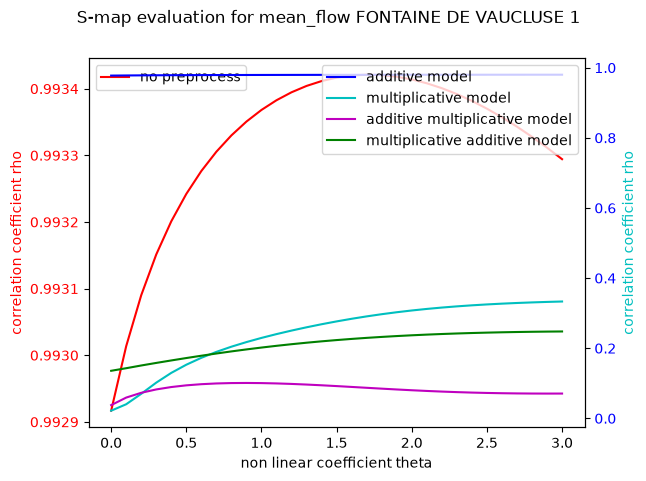

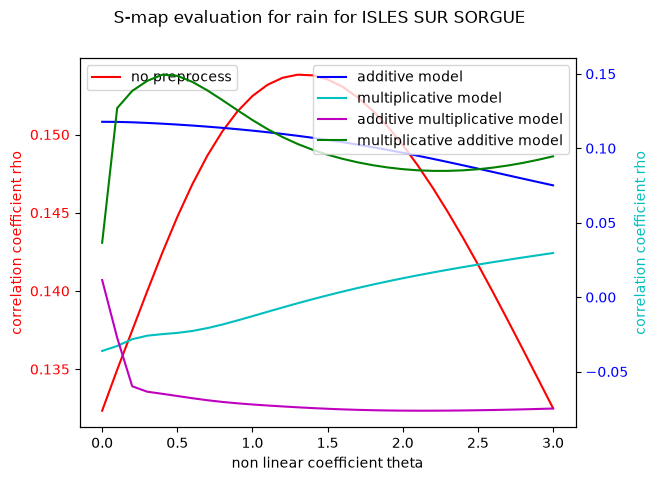

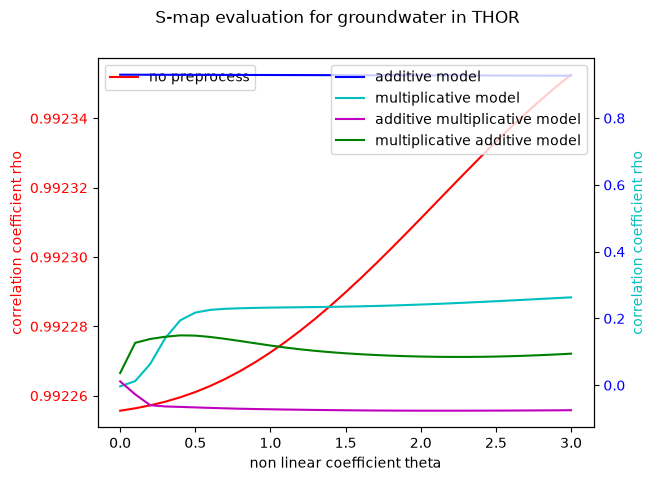

In [ ]:
lib = "1 1000"
pred = "1001 3000"

s_map = fun.run_smap(river_flow, 2, lib=lib, pred=pred)
s_map_m = fun.run_smap(river_flow_m, 5, lib=lib, pred=pred)
s_map_a = fun.run_smap(river_flow_a, 2, lib=lib, pred=pred)
s_map_am = fun.run_smap(river_flow_am, 4, lib=lib, pred=pred)
s_map_ma = fun.run_smap(river_flow_ma, 3, lib=lib, pred=pred)


fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(s_map['theta'], s_map['rho'], label = 'no preprocess', color='r')
ax2.plot(s_map_a['theta'], s_map_a['rho'], label = 'additive model', color='b')
ax2.plot(s_map_m['theta'], s_map_m['rho'], label = 'multiplicative model', color='c')
ax2.plot(s_map_am['theta'], s_map_am['rho'], label = 'additive multiplicative model', color='m')
ax2.plot(s_map_ma['theta'], s_map_ma['rho'], label = 'multiplicative additive model', color='g')

fig.suptitle('S-map evaluation for mean_flow FONTAINE DE VAUCLUSE 1')
ax1.set_xlabel('non linear coefficient theta')
ax1.set_ylabel('correlation coefficient rho', color='r')
ax2.set_ylabel('correlation coefficient rho', color='c')
ax1.tick_params(axis='y', labelcolor='r')
ax2.tick_params(axis='y', labelcolor='b')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

s_map_rain = fun.run_smap(rain_, 6, lib=lib, pred=pred)
s_map_rain_m = fun.run_smap(rain_m, 6, lib=lib, pred=pred)
s_map_rain_a = fun.run_smap(rain_a, 3, lib=lib, pred=pred)
s_map_rain_ma = fun.run_smap(rain_ma, 4, lib=lib, pred=pred)
s_map_rain_am = fun.run_smap(rain_am, 3, lib=lib, pred=pred)


fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(s_map_rain['theta'], s_map_rain['rho'], label = 'no preprocess', color='r')
ax2.plot(s_map_rain_a['theta'], s_map_rain_a['rho'], label = 'additive model', color='b')
ax2.plot(s_map_rain_m['theta'], s_map_rain_m['rho'], label = 'multiplicative model', color='c')
ax2.plot(s_map_rain_am['theta'], s_map_rain_am['rho'], label = 'additive multiplicative model', color='m')
ax2.plot(s_map_rain_ma['theta'], s_map_rain_ma['rho'], label = 'multiplicative additive model', color='g')
fig.suptitle('S-map evaluation for rain for ISLES SUR SORGUE')
ax1.set_xlabel('non linear coefficient theta')
ax1.set_ylabel('correlation coefficient rho', color='r')
ax2.set_ylabel('correlation coefficient rho', color='c')
ax1.tick_params(axis='y', labelcolor='r')
ax2.tick_params(axis='y', labelcolor='b')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

s_map_gw = fun.run_smap(depth, 2, lib=lib, pred=pred)
s_map_gw_m = fun.run_smap(depth_m, 7, lib=lib, pred=pred)
s_map_gw_a = fun.run_smap(depth_a, 2, lib=lib, pred=pred)
s_map_gw_ma = fun.run_smap(depth_ma, 4, lib=lib, pred=pred)
s_map_gw_am = fun.run_smap(depth_am, 3, lib=lib, pred=pred)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(s_map_gw['theta'], s_map_gw['rho'], label = 'no preprocess', color='r')
ax2.plot(s_map_gw_a['theta'], s_map_gw_a['rho'], label = 'additive model', color='b')
ax2.plot(s_map_gw_m['theta'], s_map_gw_m['rho'], label = 'multiplicative model', color='c')
ax2.plot(s_map_gw_am['theta'], s_map_gw_am['rho'], label = 'additive multiplicative model', color='m')
ax2.plot(s_map_gw_ma['theta'], s_map_gw_ma['rho'], label = 'multiplicative additive model', color='g')
fig.suptitle('S-map evaluation for groundwater in THOR')
ax1.set_xlabel('non linear coefficient theta')
ax1.set_ylabel('correlation coefficient rho', color='r')
ax2.set_ylabel('correlation coefficient rho', color='c')
ax1.tick_params(axis='y', labelcolor='r')
ax2.tick_params(axis='y', labelcolor='b')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

![title](img/theta_flow.png)
![title](img/theta_rain.png)